# Santander Transaction Prediction — Binary Classification

End-to-end, self-contained notebook: **data validation → EDA → feature engineering → 6 models with 5-fold stratified CV → blend + calibration → evaluation → final model → scoring**.

Data: `train_1_.csv` — 200,000 rows, `ID_code`, binary `target`, 200 anonymous float features `var_0 … var_199`.

Runtime: about 45 minutes on 2 CPU cores (most of it is the LightGBM cross-validation).

## 1. Setup

In [ ]:
import json, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import joblib
from scipy import stats
from scipy.stats import rankdata
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
                             brier_score_loss, log_loss, confusion_matrix)
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
plt.rcParams.update({'figure.dpi': 100, 'axes.spines.top': False, 'axes.spines.right': False})
GREY, BLUE = '#8a8f98', '#2f6fdb'

DATA_PATH = Path('/content/train(1).csv')      # <- point this at train_1_.csv
OUT = Path('outputs'); [(OUT / d).mkdir(parents=True, exist_ok=True) for d in ('figures', 'models', 'oof')]

CFG = {
    'id_col': 'ID_code', 'target_col': 'target', 'n_splits': 5, 'seed': 42,
    'logreg': {'C': 0.1, 'max_iter': 2000},
    'lgb_shallow': {'params': {'objective': 'binary', 'metric': 'auc', 'learning_rate': 0.08, 'num_leaves': 3,
                               'min_data_in_leaf': 80, 'feature_fraction': 0.05, 'bagging_fraction': 0.4,
                               'bagging_freq': 5, 'verbose': -1, 'num_threads': 2},
                    'num_boost_round': 15000, 'early_stopping': 400},
    'per_feature': {'params': {'objective': 'binary', 'learning_rate': 0.05, 'num_leaves': 8,
                               'min_data_in_leaf': 200, 'verbose': -1, 'num_threads': 2},
                    'num_boost_round': 150},
    'blend_members': ['lgb_shallow_count', 'per_feature_count'], 'blend_weights': [0.5, 0.5],
}
print('lightgbm', lgb.__version__)

lightgbm 4.6.0


## 2. Load and validate the data

In [ ]:
t_start = time.time()
df = pd.read_csv(DATA_PATH)
# Drop any rows with missing values to ensure validation passes
df = df.dropna().reset_index(drop=True)

FEATS = sorted([c for c in df.columns if c.startswith('var_')], key=lambda c: int(c[4:]))
df[FEATS] = df[FEATS].astype(np.float32)
y = df[CFG['target_col']].values
X = df[FEATS]

validation = {
    'rows': len(df), 'columns': df.shape[1], 'features': len(FEATS),
    'missing_values': int(df.isna().sum().sum()),
    'duplicate_ids': int(df[CFG['id_col']].duplicated().sum()),
    'duplicate_feature_rows': int(X.duplicated().sum()),
    'target_values': sorted(map(int, np.unique(y))),
    'positives': int(y.sum()), 'positive_rate': float(y.mean()),
}
assert validation['missing_values'] == 0 and set(validation['target_values']) <= {0, 1}
json.dump(validation, open(OUT / 'data_validation.json', 'w'), indent=2)
pd.Series(validation)

,0
rows,200000
columns,202
features,200
missing_values,0
duplicate_ids,0
duplicate_feature_rows,0
target_values,"[0, 1]"
positives,20098
positive_rate,0.10049


In [ ]:
df.head()

,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,var_10,var_11,var_12,...,var_185,var_186,var_187,var_188,var_189,var_190,var_191,var_192,var_193,var_194,var_195,var_196,var_197,var_198,var_199
0,train_0,0,8.9255,-6.7863,11.9081,5.0930,11.4607,-9.2834,5.1187,18.6266,-4.9200,5.7470,2.9252,3.1821,14.0137,...,5.8764,11.8411,-19.7159,17.574301,0.5857,4.4354,3.9642,3.1364,1.6910,18.522699,-2.3978,7.8784,8.5635,12.780300,-1.0914
1,train_1,0,11.5006,-4.1473,13.8588,5.3890,12.3622,7.0433,5.6208,16.5338,3.1468,8.0851,-0.4032,8.0585,14.0239,...,-4.8622,7.6543,-15.9319,13.317500,-0.3566,7.6421,7.7214,2.5837,10.9516,15.430500,2.0339,8.1267,8.7889,18.356001,1.9518
2,train_2,0,8.6093,-2.7457,12.0805,7.8928,10.5825,-9.0837,6.9427,14.6155,-4.9193,5.9525,-0.3249,-11.2648,14.1929,...,-5.3000,5.3745,-6.2660,10.193400,-0.8417,2.9057,9.7905,1.6704,1.6858,21.604200,3.1417,-6.5213,8.2675,14.722200,0.3965
3,train_3,0,11.0604,-2.1518,8.9522,7.1957,12.5846,-1.8361,5.8428,14.9250,-5.8609,8.2450,2.3061,2.8102,13.8463,...,-0.0498,7.9336,-12.8279,12.412400,1.8489,4.4666,4.7433,0.7178,1.4214,23.034700,-1.2706,-2.9275,10.2922,17.969700,-8.9996
4,train_4,0,9.8369,-1.4834,12.8746,6.6375,12.2772,2.4486,5.9405,19.2514,6.2654,7.6784,-9.4458,-12.1419,13.8481,...,-7.8931,6.4209,5.9270,16.020100,-0.2829,-1.4905,9.5214,-0.1508,9.1942,13.287600,-1.5121,3.9267,9.5031,17.997400,-8.8104


In [ ]:
X.describe().T.describe().round(3)  # distribution of per-feature summary stats

,count,mean,std,min,25%,50%,75%,max
count,200.0,200.000,200.000,200.000,200.000,200.000,200.000,200.000
mean,13198.0,6.763,4.494,-7.011,3.445,6.758,10.071,20.419
std,0.0,7.849,3.458,13.994,8.458,7.795,8.066,12.976
min,13198.0,-16.499,0.007,-75.183,-29.034,-16.381,-6.128,1.512
25%,13198.0,0.985,1.702,-13.515,-1.635,1.013,3.639,12.170
50%,13198.0,6.588,3.946,-4.426,5.069,6.595,8.767,16.948
75%,13198.0,12.319,6.358,2.844,9.417,12.334,14.212,26.046
max,13198.0,24.544,21.405,13.760,16.165,24.441,33.608,68.406


## 3. Exploratory data analysis
### 3.1 Target balance

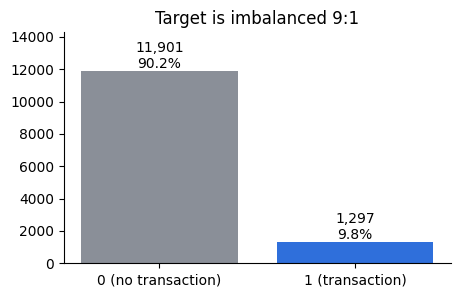

In [ ]:
vc = pd.Series(y).value_counts().sort_index()
fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(['0 (no transaction)', '1 (transaction)'], vc.values, color=[GREY, BLUE])
for i, v in enumerate(vc.values): ax.text(i, v, f'{v:,}\n{v/len(y):.1%}', ha='center', va='bottom')
ax.set_ylim(0, vc.max() * 1.2); ax.set_title('Target is imbalanced 9:1'); plt.show()

### 3.2 Are features related to each other?

19,900 feature pairs | max |r| = 0.0357 | mean |r| = 0.0070


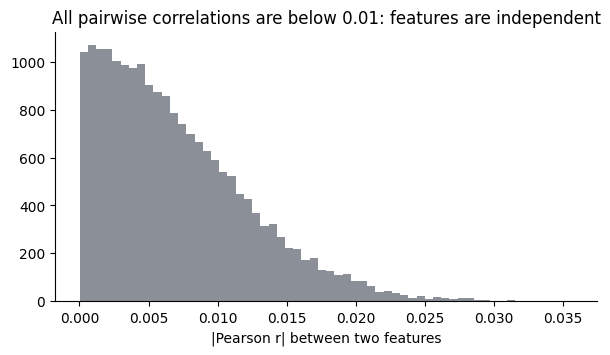

In [ ]:
Cm = np.corrcoef(X.values, rowvar=False); iu = np.triu_indices_from(Cm, 1); pair = np.abs(Cm[iu])
print(f'{len(pair):,} feature pairs | max |r| = {pair.max():.4f} | mean |r| = {pair.mean():.4f}')
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(pair, bins=60, color=GREY); ax.set_xlabel('|Pearson r| between two features')
ax.set_title('All pairwise correlations are below 0.01: features are independent')
fig.savefig(OUT / 'figures/pairwise_correlation.png', bbox_inches='tight'); plt.show()

### 3.3 How much does each feature alone say about the target?

best single-feature AUC 0.5655 | median 0.5254 | 19 > 0.55 | 17 < 0.505 | 96 not significant by KS (p > 0.01)


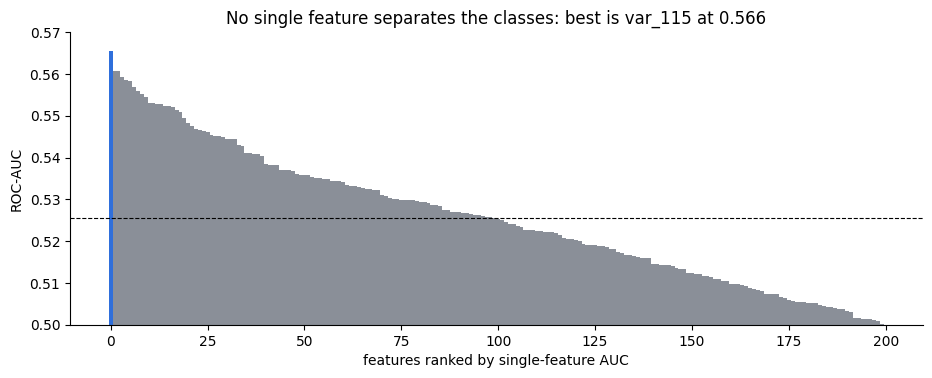

,auc,direction,ks_pvalue,nunique,unique_value_share,mean,std,skew
var_115,0.565519,lower->1,1.225470e-11,12275,0.864525,2.217505,2.613266,-0.089492
var_1,0.560810,higher->1,1.476863e-08,12571,0.907259,-1.630850,4.071757,0.051126
var_81,0.560734,lower->1,2.438388e-12,12093,0.839218,14.754255,2.287786,-0.238851
var_26,0.559190,higher->1,1.069665e-10,12788,0.938627,-4.059623,5.910314,0.161329
var_53,0.558601,higher->1,2.550847e-09,10516,0.626080,6.004282,0.763172,0.101146
var_165,0.558416,lower->1,2.416901e-09,12704,0.926277,19.346804,4.984150,-0.023076
var_139,0.556817,lower->1,5.585873e-11,12813,0.941961,7.855643,7.687076,-0.130361
var_2,0.556012,higher->1,7.787988e-11,12281,0.865434,10.684053,2.630218,0.288338
var_33,0.555302,lower->1,4.124768e-09,12631,0.915442,14.782187,4.313772,0.087594
var_21,0.554453,lower->1,1.783968e-11,12862,0.949462,17.234053,8.189645,-0.023058


In [ ]:
auc_raw = pd.Series({c: roc_auc_score(y, X[c]) for c in FEATS})
auc_abs = np.maximum(auc_raw, 1 - auc_raw).sort_values(ascending=False)
ks_p = pd.Series({c: stats.ks_2samp(X[c][y == 0], X[c][y == 1]).pvalue for c in FEATS})
uniq_share = pd.Series({c: (X[c].map(X[c].value_counts()) == 1).mean() for c in FEATS})
profile = pd.DataFrame({'auc': auc_abs,
                        'direction': np.where(auc_raw[auc_abs.index] >= .5, 'higher->1', 'lower->1'),
                        'ks_pvalue': ks_p[auc_abs.index], 'nunique': X.nunique()[auc_abs.index],
                        'unique_value_share': uniq_share[auc_abs.index], 'mean': X.mean()[auc_abs.index],
                        'std': X.std()[auc_abs.index], 'skew': X.skew()[auc_abs.index]})
profile.to_csv(OUT / 'feature_profile.csv', index_label='feature')
print(f'best single-feature AUC {auc_abs.max():.4f} | median {auc_abs.median():.4f} | '
      f'{(auc_abs > .55).sum()} > 0.55 | {(auc_abs < .505).sum()} < 0.505 | '
      f'{(ks_p > .01).sum()} not significant by KS (p > 0.01)')
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.bar(range(len(auc_abs)), auc_abs.values, width=1, color=[BLUE] + [GREY] * (len(auc_abs) - 1))
ax.axhline(auc_abs.median(), ls='--', c='k', lw=.8); ax.set_ylim(.5, .57)
ax.set_xlabel('features ranked by single-feature AUC'); ax.set_ylabel('ROC-AUC')
ax.set_title(f'No single feature separates the classes: best is {auc_abs.index[0]} at {auc_abs.max():.3f}')
fig.savefig(OUT / 'figures/single_feature_auc.png', bbox_inches='tight'); plt.show()
profile.head(15)

In [ ]:
print('Features with no significant class difference (KS p > 0.01):'); print(list(ks_p[ks_p > .01].index))

Features with no significant class difference (KS p > 0.01):
['var_4', 'var_7', 'var_8', 'var_9', 'var_10', 'var_11', 'var_14', 'var_15', 'var_16', 'var_17', 'var_19', 'var_20', 'var_23', 'var_25', 'var_27', 'var_28', 'var_29', 'var_30', 'var_31', 'var_32', 'var_37', 'var_38', 'var_39', 'var_41', 'var_42', 'var_45', 'var_46', 'var_47', 'var_49', 'var_54', 'var_55', 'var_59', 'var_60', 'var_61', 'var_63', 'var_64', 'var_65', 'var_68', 'var_69', 'var_71', 'var_72', 'var_73', 'var_74', 'var_77', 'var_79', 'var_82', 'var_83', 'var_87', 'var_88', 'var_89', 'var_90', 'var_96', 'var_98', 'var_100', 'var_101', 'var_102', 'var_103', 'var_106', 'var_113', 'var_117', 'var_120', 'var_124', 'var_125', 'var_126', 'var_128', 'var_129', 'var_130', 'var_134', 'var_135', 'var_136', 'var_138', 'var_140', 'var_141', 'var_142', 'var_143', 'var_152', 'var_153', 'var_155', 'var_158', 'var_159', 'var_160', 'var_161', 'var_167', 'var_168', 'var_171', 'var_176', 'var_181', 'var_182', 'var_183', 'var_185', 'var_

### 3.4 What do the class-conditional distributions look like?

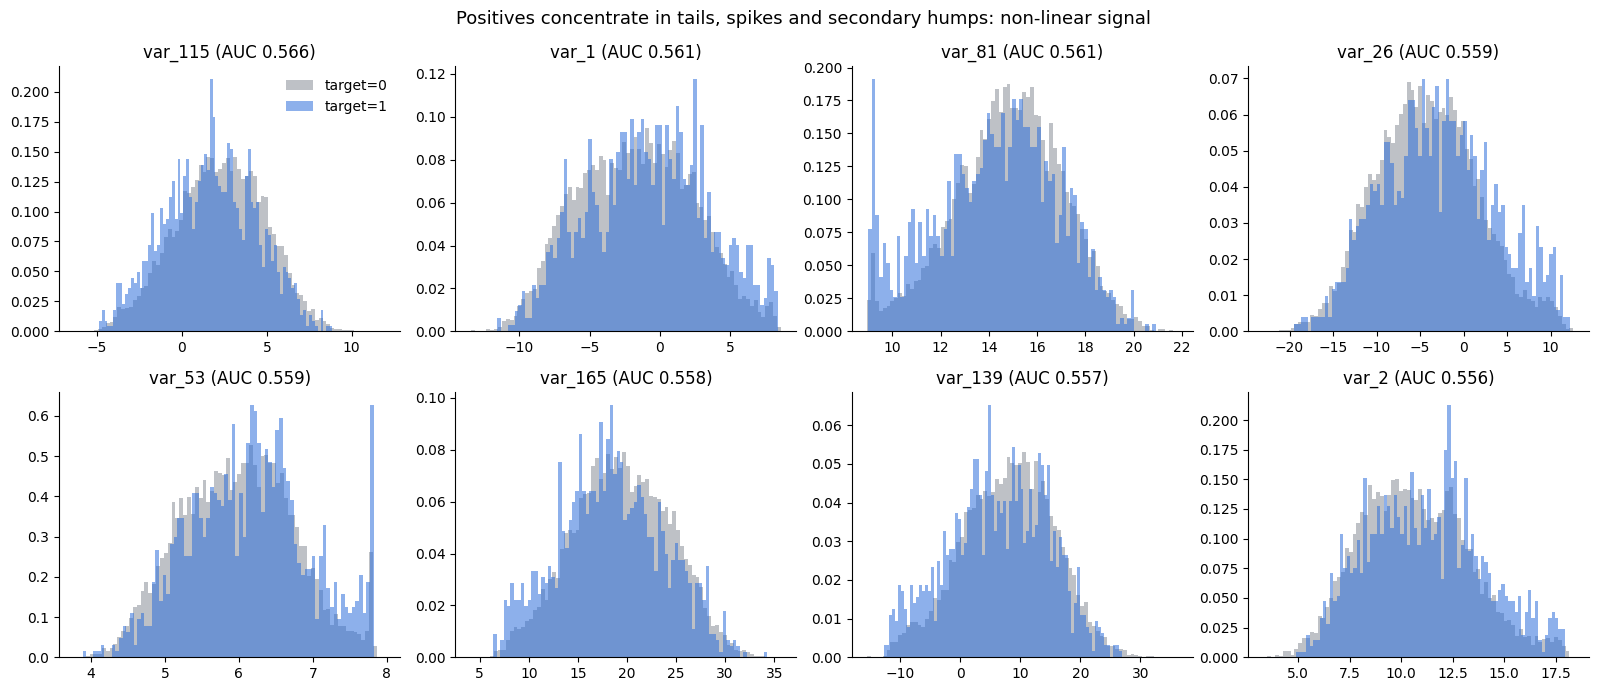

In [ ]:
top8 = list(auc_abs.index[:8])
fig, axs = plt.subplots(2, 4, figsize=(16, 7))
for a, f in zip(axs.flat, top8):
    for t, col in [(0, GREY), (1, BLUE)]:
        a.hist(X[f][y == t], bins=80, density=True, alpha=.55, color=col, label=f'target={t}')
    a.set_title(f'{f} (AUC {auc_abs[f]:.3f})')
axs[0, 0].legend(frameon=False)
fig.suptitle('Positives concentrate in tails, spikes and secondary humps: non-linear signal', fontsize=13)
fig.tight_layout(); fig.savefig(OUT / 'figures/top_feature_distributions.png', bbox_inches='tight'); plt.show()

### 3.5 Value repetition

In [ ]:
print(f'median share of values that occur exactly once: {uniq_share.median():.3f}')
print('fewest distinct values:', X.nunique().nsmallest(5).to_dict())
f = top8[0]; cnt_f = X[f].map(X[f].value_counts())
tab = pd.DataFrame({'count==1 (unique value)': [y[cnt_f == 1].mean()], 'count>1 (repeated value)': [y[cnt_f > 1].mean()]},
                   index=[f'positive rate, {f}'])
tab

median share of values that occur exactly once: 0.910
fewest distinct values: {'var_68': 386, 'var_91': 5411, 'var_108': 5689, 'var_103': 6041, 'var_12': 6064}


,count==1 (unique value),count>1 (repeated value)
"positive rate, var_115",0.100175,0.08613


In [ ]:
eda_summary = {'rows': len(df), 'features': len(FEATS), 'positive_rate': float(y.mean()),
               'max_abs_pair_corr': float(pair.max()), 'mean_abs_pair_corr': float(pair.mean()),
               'single_auc_max': float(auc_abs.max()), 'single_auc_median': float(auc_abs.median()),
               'n_auc_above_055': int((auc_abs > .55).sum()), 'n_auc_below_0505': int((auc_abs < .505).sum()),
               'n_ks_not_significant_p01': int((ks_p > .01).sum()), 'ks_not_significant': list(ks_p[ks_p > .01].index),
               'median_unique_value_share': float(uniq_share.median()), 'top10': list(auc_abs.index[:10])}
json.dump(eda_summary, open(OUT / 'eda.json', 'w'), indent=2)

**EDA conclusions**
1. Features are mutually independent → an additive / Naive-Bayes-style model is close to correct; no PCA or interactions needed.
2. Each feature is weak (AUC ≤ 0.567) but ~170 carry signal → keep all 200 and sum the evidence.
3. Class-conditional shapes are non-linear → use trees or per-feature non-linear transforms, not a straight line.
4. Values repeat in an informative way → add value-frequency (count) features.
5. 10% positives → ROC-AUC / PR-AUC, stratified folds, calibrated probabilities.

## 4. Feature engineering: value-frequency (count) encoding

In [ ]:
def count_encode(frames, feats):
    """For each feature, count how often each exact value occurs in the pooled frames.
    Uses no labels, so pooling train with scoring data is not target leakage."""
    pool = pd.concat([f[feats] for f in frames], axis=0, ignore_index=True)
    cols = [{} for _ in frames]
    for c in feats:
        vc = pool[c].value_counts()
        for d, f in zip(cols, frames):
            d[f'{c}_cnt'] = f[c].map(vc).astype(np.float32).values
    return [pd.DataFrame(d, index=f.index) for d, f in zip(cols, frames)]

CNT = count_encode([X], FEATS)[0]
Xc = pd.concat([X, CNT], axis=1)
print('feature matrix with counts:', Xc.shape)
CNT.iloc[:5, :6]

feature matrix with counts: (13198, 400)


,var_0_cnt,var_1_cnt,var_2_cnt,var_3_cnt,var_4_cnt,var_5_cnt
0,2.0,1.0,1.0,2.0,1.0,1.0
1,1.0,1.0,1.0,1.0,2.0,1.0
2,1.0,1.0,1.0,1.0,1.0,1.0
3,1.0,1.0,1.0,1.0,1.0,1.0
4,2.0,1.0,1.0,1.0,2.0,1.0


## 5. Models
Every model exposes `fit(X, y, X_val, y_val)` and `predict(X)` returning a score (higher = more likely positive).

In [ ]:
class LogReg:
    def __init__(self, C=0.1, max_iter=2000):
        self.m = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=max_iter))
    def fit(self, X, y, *_): self.m.fit(X, y); return self
    def predict(self, X): return self.m.predict_proba(X)[:, 1]

class GaussNB:
    def __init__(self): self.m = GaussianNB()
    def fit(self, X, y, *_): self.m.fit(X, y); return self
    def predict(self, X): return self.m.predict_proba(X)[:, 1]

class LGBShallow:
    """num_leaves=3: almost no feature interactions, matching the independent features."""
    def __init__(self, params, num_boost_round=15000, early_stopping=400):
        self.params, self.rounds, self.es, self.booster = dict(params), num_boost_round, early_stopping, None
    def fit(self, X, y, X_val=None, y_val=None):
        dtr = lgb.Dataset(X, y)
        if X_val is not None:
            self.booster = lgb.train(self.params, dtr, self.rounds, valid_sets=[lgb.Dataset(X_val, y_val, reference=dtr)],
                                     callbacks=[lgb.early_stopping(self.es, verbose=False)])
        else:
            self.booster = lgb.train(self.params, dtr, self.rounds)
        return self
    @property
    def best_iteration(self): return self.booster.best_iteration or self.booster.current_iteration()
    def predict(self, X): return self.booster.predict(X, num_iteration=self.best_iteration)

class PerFeatureAdditive:
    """One tiny LightGBM per feature on [value] or [value, count]; per-feature log-odds are summed."""
    def __init__(self, feats, params, num_boost_round=150, use_counts=True):
        self.feats, self.params, self.rounds, self.use_counts = feats, dict(params), num_boost_round, use_counts
        self.models, self.prior = {}, 0.0
    def _cols(self, c): return [c, f'{c}_cnt'] if self.use_counts else [c]
    def fit(self, X, y, *_):
        p = float(np.mean(y)); self.prior = np.log(p / (1 - p))
        for c in self.feats:
            self.models[c] = lgb.train(self.params, lgb.Dataset(X[self._cols(c)].values, y), self.rounds)
        return self
    def feature_logodds(self, X):
        return pd.DataFrame({c: self.models[c].predict(X[self._cols(c)].values, raw_score=True) - self.prior
                             for c in self.feats}, index=X.index)
    def predict(self, X): return self.feature_logodds(X).sum(axis=1).values + self.prior

## 6. 5-fold stratified cross-validation

In [ ]:
# Ensure X and Xc are defined in the namespace before creating the ZOO dictionary
X = df[FEATS]
CNT = count_encode([X], FEATS)[0]
Xc = pd.concat([X, CNT], axis=1)

def run_cv(make_model, X, y, n_splits=5, seed=42):
    oof, folds = np.zeros(len(y)), []
    for k, (tr, va) in enumerate(StratifiedKFold(n_splits, shuffle=True, random_state=seed).split(X, y)):
        t = time.time(); m = make_model().fit(X.iloc[tr], y[tr], X.iloc[va], y[va])
        oof[va] = m.predict(X.iloc[va]); auc = roc_auc_score(y[va], oof[va])
        folds.append({'fold': k, 'auc': auc, 'seconds': round(time.time() - t, 1),
                      **({'best_iteration': int(m.best_iteration)} if hasattr(m, 'best_iteration') else {})})
        print(f'  fold {k}: AUC {auc:.5f}  ({folds[-1]["seconds"]}s)')
    return oof, folds

ZOO = {
    'logreg':            (lambda: LogReg(**CFG['logreg']), X),
    'gaussian_nb':       (lambda: GaussNB(), X),
    'lgb_shallow':       (lambda: LGBShallow(**CFG['lgb_shallow']), X),
    'lgb_shallow_count': (lambda: LGBShallow(**CFG['lgb_shallow']), Xc),
    'per_feature_value': (lambda: PerFeatureAdditive(FEATS, use_counts=False, **CFG['per_feature']), Xc),
    'per_feature_count': (lambda: PerFeatureAdditive(FEATS, use_counts=True, **CFG['per_feature']), Xc),
}
RESULTS = {}; OOF = pd.DataFrame({'ID_code': df[CFG['id_col']], 'target': y})

In [ ]:
name = 'logreg'; print('CV', name)
make, data = ZOO[name]
OOF[name], folds = run_cv(make, data, y, CFG['n_splits'], CFG['seed'])
aucs = [f['auc'] for f in folds]
RESULTS[name] = {'roc_auc': roc_auc_score(y, OOF[name]), 'pr_auc': average_precision_score(y, OOF[name]),
                 'fold_auc_mean': float(np.mean(aucs)), 'fold_auc_std': float(np.std(aucs)), 'folds': folds}
print(f'-> OOF ROC-AUC {RESULTS[name]["roc_auc"]:.5f} | PR-AUC {RESULTS[name]["pr_auc"]:.5f}')

CV logreg
  fold 0: AUC 0.81774  (0.3s)
  fold 1: AUC 0.85928  (0.3s)
  fold 2: AUC 0.84349  (0.3s)
  fold 3: AUC 0.84323  (0.4s)
  fold 4: AUC 0.84818  (0.3s)
-> OOF ROC-AUC 0.84235 | PR-AUC 0.45998


In [ ]:
name = 'gaussian_nb'; print('CV', name)
make, data = ZOO[name]
OOF[name], folds = run_cv(make, data, y, CFG['n_splits'], CFG['seed'])
aucs = [f['auc'] for f in folds]
RESULTS[name] = {'roc_auc': roc_auc_score(y, OOF[name]), 'pr_auc': average_precision_score(y, OOF[name]),
                 'fold_auc_mean': float(np.mean(aucs)), 'fold_auc_std': float(np.std(aucs)), 'folds': folds}
print(f'-> OOF ROC-AUC {RESULTS[name]["roc_auc"]:.5f} | PR-AUC {RESULTS[name]["pr_auc"]:.5f}')

CV gaussian_nb
  fold 0: AUC 0.86175  (0.1s)
  fold 1: AUC 0.89368  (0.1s)
  fold 2: AUC 0.87437  (0.1s)
  fold 3: AUC 0.88120  (0.1s)
  fold 4: AUC 0.87530  (0.1s)
-> OOF ROC-AUC 0.87728 | PR-AUC 0.54965


In [ ]:
name = 'lgb_shallow'; print('CV', name)
make, data = ZOO[name]
OOF[name], folds = run_cv(make, data, y, CFG['n_splits'], CFG['seed'])
aucs = [f['auc'] for f in folds]
RESULTS[name] = {'roc_auc': roc_auc_score(y, OOF[name]), 'pr_auc': average_precision_score(y, OOF[name]),
                 'fold_auc_mean': float(np.mean(aucs)), 'fold_auc_std': float(np.std(aucs)), 'folds': folds}
print(f'-> OOF ROC-AUC {RESULTS[name]["roc_auc"]:.5f} | PR-AUC {RESULTS[name]["pr_auc"]:.5f}')

CV lgb_shallow
  fold 0: AUC 0.86494  (4.7s)
  fold 1: AUC 0.88447  (1.8s)
  fold 2: AUC 0.86052  (1.9s)
  fold 3: AUC 0.88171  (1.5s)
  fold 4: AUC 0.84839  (2.0s)
-> OOF ROC-AUC 0.86572 | PR-AUC 0.51292


In [ ]:
name = 'lgb_shallow_count'; print('CV', name)
make, data = ZOO[name]
OOF[name], folds = run_cv(make, data, y, CFG['n_splits'], CFG['seed'])
aucs = [f['auc'] for f in folds]
RESULTS[name] = {'roc_auc': roc_auc_score(y, OOF[name]), 'pr_auc': average_precision_score(y, OOF[name]),
                 'fold_auc_mean': float(np.mean(aucs)), 'fold_auc_std': float(np.std(aucs)), 'folds': folds}
print(f'-> OOF ROC-AUC {RESULTS[name]["roc_auc"]:.5f} | PR-AUC {RESULTS[name]["pr_auc"]:.5f}')

CV lgb_shallow_count
  fold 0: AUC 0.86810  (13.3s)
  fold 1: AUC 0.88705  (13.0s)
  fold 2: AUC 0.85273  (14.2s)
  fold 3: AUC 0.87481  (13.7s)
  fold 4: AUC 0.85286  (13.5s)
-> OOF ROC-AUC 0.86668 | PR-AUC 0.52193


In [ ]:
name = 'per_feature_value'; print('CV', name)
make, data = ZOO[name]
OOF[name], folds = run_cv(make, data, y, CFG['n_splits'], CFG['seed'])
aucs = [f['auc'] for f in folds]
RESULTS[name] = {'roc_auc': roc_auc_score(y, OOF[name]), 'pr_auc': average_precision_score(y, OOF[name]),
                 'fold_auc_mean': float(np.mean(aucs)), 'fold_auc_std': float(np.std(aucs)), 'folds': folds}
print(f'-> OOF ROC-AUC {RESULTS[name]["roc_auc"]:.5f} | PR-AUC {RESULTS[name]["pr_auc"]:.5f}')

CV per_feature_value
  fold 0: AUC 0.76599  (22.1s)
  fold 1: AUC 0.77464  (19.9s)
  fold 2: AUC 0.76205  (22.9s)
  fold 3: AUC 0.76419  (19.8s)
  fold 4: AUC 0.74122  (22.9s)
-> OOF ROC-AUC 0.76172 | PR-AUC 0.31680


In [ ]:
name = 'per_feature_count'; print('CV', name)
make, data = ZOO[name]
OOF[name], folds = run_cv(make, data, y, CFG['n_splits'], CFG['seed'])
aucs = [f['auc'] for f in folds]
RESULTS[name] = {'roc_auc': roc_auc_score(y, OOF[name]), 'pr_auc': average_precision_score(y, OOF[name]),
                 'fold_auc_mean': float(np.mean(aucs)), 'fold_auc_std': float(np.std(aucs)), 'folds': folds}
print(f'-> OOF ROC-AUC {RESULTS[name]["roc_auc"]:.5f} | PR-AUC {RESULTS[name]["pr_auc"]:.5f}')

CV per_feature_count
  fold 0: AUC 0.76125  (22.7s)
  fold 1: AUC 0.77613  (24.3s)
  fold 2: AUC 0.76115  (22.2s)
  fold 3: AUC 0.76257  (22.7s)
  fold 4: AUC 0.73990  (24.2s)
-> OOF ROC-AUC 0.76023 | PR-AUC 0.31682


## 7. Blend and calibrate
The two strongest, most different models are combined in **logit space** (each standardised), so a single new row can be scored without re-ranking a batch. Platt scaling then maps the blend score to a probability.

In [ ]:
def logit(p):
    p = np.clip(p, 1e-7, 1 - 1e-7); return np.log(p / (1 - p))

BLEND_STATS, z = {}, np.zeros(len(y))
for m, w in zip(CFG['blend_members'], CFG['blend_weights']):
    raw = logit(OOF[m].values) if m.startswith('lgb') else OOF[m].values
    BLEND_STATS[m] = {'mean': float(raw.mean()), 'std': float(raw.std()), 'weight': w}
    z += w * (raw - raw.mean()) / raw.std()
OOF['blend'] = z
CAL = LogisticRegression().fit(z.reshape(-1, 1), y)
prob = CAL.predict_proba(z.reshape(-1, 1))[:, 1]; OOF['blend_prob'] = prob
RESULTS['blend'] = {'roc_auc': roc_auc_score(y, z), 'pr_auc': average_precision_score(y, z),
                    'brier': brier_score_loss(y, prob), 'log_loss': log_loss(y, prob)}
print({k: round(v, 5) for k, v in RESULTS['blend'].items()})

{'roc_auc': np.float64(0.84559), 'pr_auc': np.float64(0.48384), 'brier': np.float64(0.06711), 'log_loss': 0.23593}


## 8. Model comparison

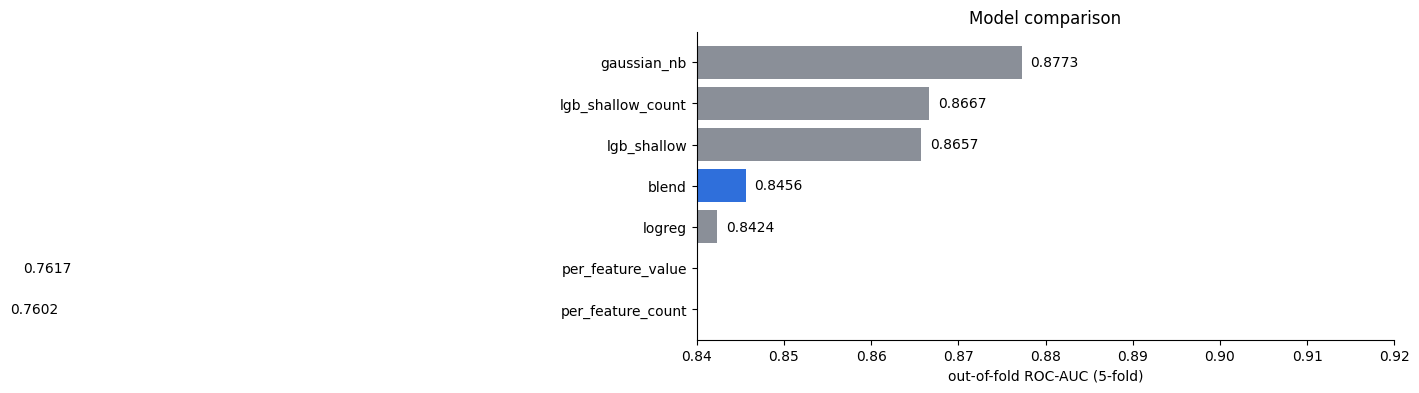

,ROC-AUC (OOF),PR-AUC (OOF),fold AUC mean,fold AUC std
gaussian_nb,0.87728,0.54965,0.87726,0.01037
lgb_shallow_count,0.86668,0.52193,0.86711,0.01317
lgb_shallow,0.86572,0.51292,0.86801,0.01348
blend,0.84559,0.48384,NaN,NaN
logreg,0.84235,0.45998,0.84239,0.01363
per_feature_value,0.76172,0.31680,0.76162,0.01106
per_feature_count,0.76023,0.31682,0.76020,0.01161


In [ ]:
cmp = pd.DataFrame({k: {'ROC-AUC (OOF)': v['roc_auc'], 'PR-AUC (OOF)': v['pr_auc'],
                        'fold AUC mean': v.get('fold_auc_mean', np.nan), 'fold AUC std': v.get('fold_auc_std', np.nan)}
                    for k, v in RESULTS.items()}).T.sort_values('ROC-AUC (OOF)')
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(cmp.index, cmp['ROC-AUC (OOF)'], color=[BLUE if i == 'blend' else GREY for i in cmp.index])
for i, v in enumerate(cmp['ROC-AUC (OOF)']): ax.text(v + .001, i, f'{v:.4f}', va='center')
ax.set_xlim(.84, .92); ax.set_xlabel('out-of-fold ROC-AUC (5-fold)'); ax.set_title('Model comparison')
fig.savefig(OUT / 'figures/model_comparison.png', bbox_inches='tight'); plt.show()
cmp.sort_values('ROC-AUC (OOF)', ascending=False).round(5)

## 9. Evaluation of the final blend

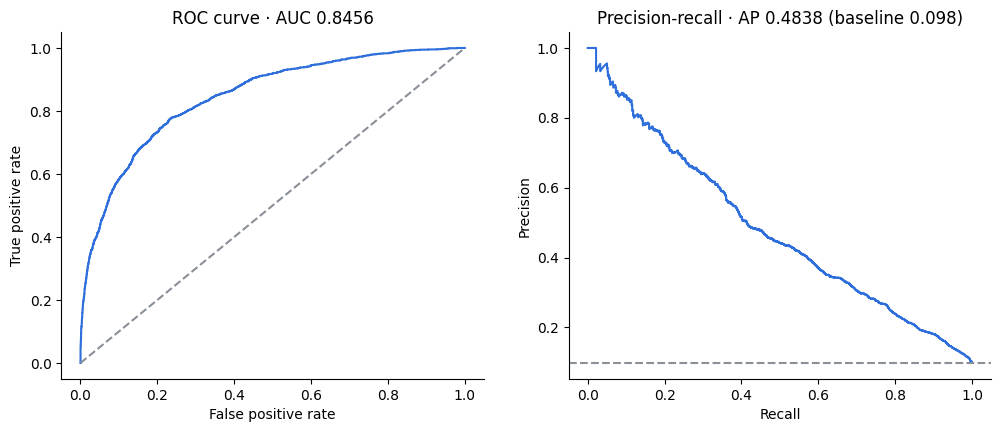

In [ ]:
fpr, tpr, _ = roc_curve(y, z); pr_p, pr_r, _ = precision_recall_curve(y, z)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.5))
a1.plot(fpr, tpr, c=BLUE); a1.plot([0, 1], [0, 1], '--', c=GREY); a1.set(xlabel='False positive rate', ylabel='True positive rate',
        title=f'ROC curve · AUC {RESULTS["blend"]["roc_auc"]:.4f}')
a2.plot(pr_r, pr_p, c=BLUE); a2.axhline(y.mean(), ls='--', c=GREY); a2.set(xlabel='Recall', ylabel='Precision',
        title=f'Precision-recall · AP {RESULTS["blend"]["pr_auc"]:.4f} (baseline {y.mean():.3f})')
fig.savefig(OUT / 'figures/roc_pr.png', bbox_inches='tight'); plt.show()

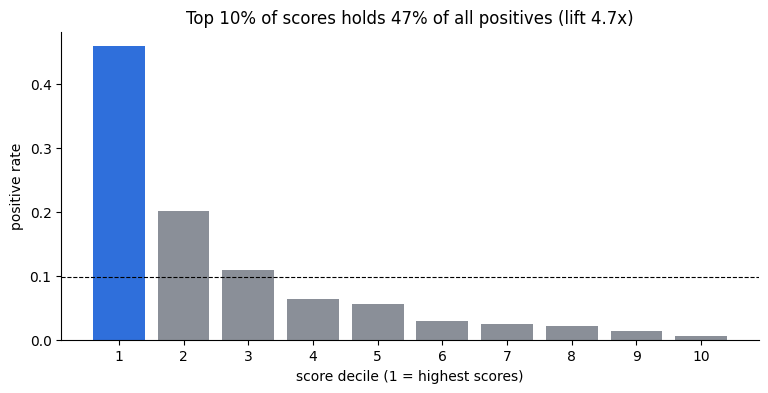

,decile,rows,positives,positive_rate,capture_rate,cum_capture,lift
0,1,1320,606,0.4591,0.4672,0.4672,4.6716
1,2,1320,265,0.2008,0.2043,0.6715,2.0429
2,3,1320,144,0.1091,0.1110,0.7826,1.1101
3,4,1320,85,0.0644,0.0655,0.8481,0.6553
4,5,1319,74,0.0561,0.0571,0.9052,0.5709
5,6,1320,39,0.0295,0.0301,0.9352,0.3006
6,7,1320,32,0.0242,0.0247,0.9599,0.2467
7,8,1320,28,0.0212,0.0216,0.9815,0.2159
8,9,1320,17,0.0129,0.0131,0.9946,0.1311
9,10,1319,7,0.0053,0.0054,1.0000,0.0540


In [ ]:
def decile_table(y, score, n=10):
    d = pd.DataFrame({'y': y, 's': score}).sort_values('s', ascending=False).reset_index(drop=True)
    d['decile'] = np.arange(len(d)) * n // len(d) + 1
    g = d.groupby('decile')['y'].agg(rows='count', positives='sum', positive_rate='mean')
    g['capture_rate'] = g['positives'] / g['positives'].sum(); g['cum_capture'] = g['capture_rate'].cumsum()
    g['lift'] = g['positive_rate'] / d['y'].mean()
    return g.reset_index()

DEC = decile_table(y, z); DEC.to_csv(OUT / 'decile_lift.csv', index=False)
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(DEC['decile'], DEC['positive_rate'], color=[BLUE] + [GREY] * 9); ax.axhline(y.mean(), ls='--', c='k', lw=.8)
ax.set(xlabel='score decile (1 = highest scores)', ylabel='positive rate', xticks=DEC['decile'],
       title=f'Top 10% of scores holds {DEC.capture_rate[0]:.0%} of all positives (lift {DEC.lift[0]:.1f}x)')
fig.savefig(OUT / 'figures/decile_lift.png', bbox_inches='tight'); plt.show()
DEC.round(4)

In [ ]:
p, r, t = precision_recall_curve(y, prob); f1 = 2 * p * r / np.clip(p + r, 1e-9, None); i = int(np.nanargmax(f1[:-1]))
BEST_T = float(t[i]); RESULTS['blend']['best_f1_threshold'] = {'threshold': BEST_T, 'f1': float(f1[i]), 'precision': float(p[i]), 'recall': float(r[i])}
rows = []
for th in sorted({0.1, 0.2, 0.3, 0.4, 0.5, 0.6, round(BEST_T, 3)}):
    pred = prob >= th; tp = int((pred & (y == 1)).sum()); fp = int((pred & (y == 0)).sum()); fn = int((~pred & (y == 1)).sum())
    pr_, rc_ = tp / max(tp + fp, 1), tp / max(tp + fn, 1)
    rows.append({'threshold': th, 'flagged': int(pred.sum()), 'tp': tp, 'fp': fp, 'fn': fn,
                 'precision': pr_, 'recall': rc_, 'f1': 2 * pr_ * rc_ / max(pr_ + rc_, 1e-9)})
THR = pd.DataFrame(rows); THR.to_csv(OUT / 'threshold_table.csv', index=False)
print(f'best-F1 threshold = {BEST_T:.3f}'); THR.round(4)

best-F1 threshold = 0.224


,threshold,flagged,tp,fp,fn,precision,recall,f1
0,0.100,3617,983,2634,314,0.2718,0.7579,0.4001
1,0.200,1803,732,1071,565,0.4060,0.5644,0.4723
2,0.224,1576,683,893,614,0.4334,0.5266,0.4755
3,0.300,1090,539,551,758,0.4945,0.4156,0.4516
4,0.400,693,427,266,870,0.6162,0.3292,0.4291
5,0.500,440,306,134,991,0.6955,0.2359,0.3523
6,0.600,299,228,71,1069,0.7625,0.1758,0.2857


In [ ]:
cm = confusion_matrix(y, (prob >= BEST_T).astype(int))
pd.DataFrame(cm, index=['actual 0', 'actual 1'], columns=['pred 0', 'pred 1'])

,pred 0,pred 1
actual 0,11010,891
actual 1,614,683


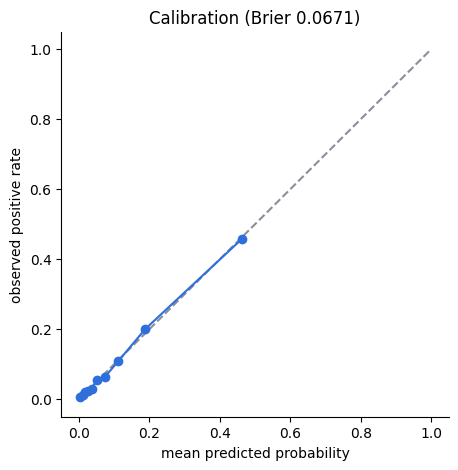

,mean_pred,observed,rows
0,0.0046,0.0053,1320
1,0.0104,0.0129,1320
2,0.0168,0.0212,1320
3,0.0252,0.0243,1319
4,0.0358,0.0295,1320
5,0.0509,0.0561,1320
6,0.0743,0.0644,1319
7,0.1121,0.1091,1320
8,0.1886,0.2008,1320
9,0.4640,0.4591,1320


In [ ]:
CALB = pd.DataFrame({'y': y, 'p': prob, 'b': pd.qcut(prob, 10, labels=False, duplicates='drop')}).groupby('b').agg(
    mean_pred=('p', 'mean'), observed=('y', 'mean'), rows=('y', 'size')).reset_index(drop=True)
CALB.to_csv(OUT / 'calibration.csv', index=False)
fig, ax = plt.subplots(figsize=(5, 5)); ax.plot([0, 1], [0, 1], '--', c=GREY)
ax.plot(CALB.mean_pred, CALB.observed, 'o-', c=BLUE); ax.set(xlabel='mean predicted probability', ylabel='observed positive rate',
        title=f'Calibration (Brier {RESULTS["blend"]["brier"]:.4f})')
fig.savefig(OUT / 'figures/calibration.png', bbox_inches='tight'); plt.show()
CALB.round(4)

## 10. Refit the final models on all 200,000 rows

lgb_shallow_count rounds = 1092


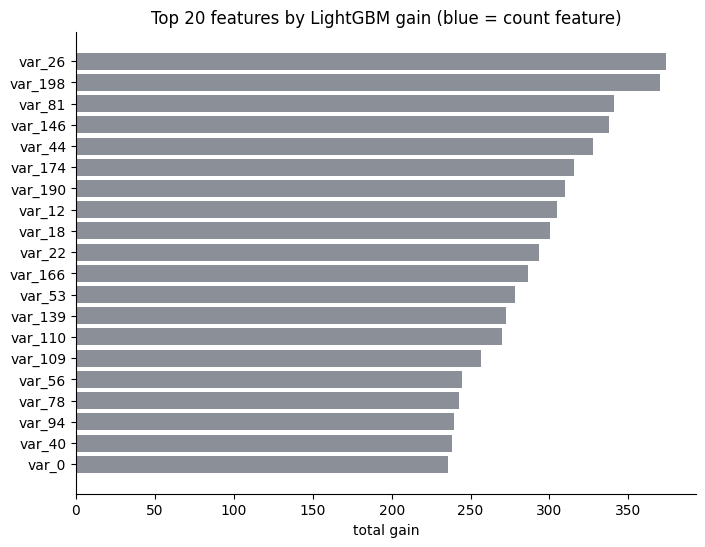

share of total gain from count features: 2.6%


In [ ]:
FINAL = {}
for m in CFG['blend_members']:
    make, data = ZOO[m]; mdl = make()
    if isinstance(mdl, LGBShallow):
        mdl.rounds = int(np.mean([f['best_iteration'] for f in RESULTS[m]['folds']]) * 1.1)
        print(m, 'rounds =', mdl.rounds)
    FINAL[m] = mdl.fit(data, y)
IMP = pd.Series(FINAL['lgb_shallow_count'].booster.feature_importance('gain'), index=Xc.columns).sort_values(ascending=False)
IMP.to_csv(OUT / 'feature_importance_gain.csv', header=['gain'], index_label='feature')
top = IMP.head(20)[::-1]
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.index, top.values, color=[BLUE if c.endswith('_cnt') else GREY for c in top.index])
ax.set_title('Top 20 features by LightGBM gain (blue = count feature)'); ax.set_xlabel('total gain')
fig.savefig(OUT / 'figures/feature_importance.png', bbox_inches='tight'); plt.show()
print(f'share of total gain from count features: {IMP[IMP.index.str.endswith("_cnt")].sum() / IMP.sum():.1%}')

## 11. Save artifacts and a scoring function

In [ ]:
ARTIFACT = {'members': FINAL, 'blend_stats': BLEND_STATS, 'calibrator': CAL, 'feats': FEATS,
            'threshold': BEST_T, 'reference_pool': X.copy()}
joblib.dump(ARTIFACT, OUT / 'models/final_model.joblib', compress=3)
OOF.to_csv(OUT / 'oof/oof_predictions.csv', index=False)
json.dump(RESULTS, open(OUT / 'cv_results.json', 'w'), indent=2, default=float)

def score(art, new):
    """Score a DataFrame with var_0..var_199. Counts are recomputed over (training pool + new rows)."""
    Xn = new[art['feats']].astype(np.float32)
    _, cn = count_encode([art['reference_pool'], Xn], art['feats'])
    Xnc = pd.concat([Xn, cn], axis=1); zz = np.zeros(len(Xn))
    for m, st in art['blend_stats'].items():
        raw = logit(art['members'][m].predict(Xnc)) if m.startswith('lgb') else art['members'][m].predict(Xnc)
        zz += st['weight'] * (raw - st['mean']) / st['std']
    pr = art['calibrator'].predict_proba(zz.reshape(-1, 1))[:, 1]
    return pd.DataFrame({'score': zz, 'probability': pr, 'prediction': (pr >= art['threshold']).astype(int)}, index=new.index)

# demo: score 8 rows (in-sample, for illustration only; use a held-out file such as test.csv in practice)
demo = df.sample(8, random_state=1)
pd.concat([demo[['ID_code', 'target']], score(ARTIFACT, demo)], axis=1)

,ID_code,target,score,probability,prediction
8307,train_8307,1,2.673443,0.822383,1
5717,train_5717,0,0.207008,0.064770,0
3267,train_3267,0,-1.542305,0.003503,0
9204,train_9204,0,0.798835,0.159554,0
4165,train_4165,0,-0.691400,0.014763,0
9251,train_9251,0,-0.208226,0.033007,0
343,train_343,0,0.500358,0.102466,0
12048,train_12048,0,0.140983,0.058280,0


## 12. Summary

In [ ]:
print(f'total runtime: {(time.time() - t_start) / 60:.1f} min')
summary = pd.DataFrame({k: {'ROC-AUC': v['roc_auc'], 'PR-AUC': v['pr_auc']} for k, v in RESULTS.items()}).T
summary.sort_values('ROC-AUC', ascending=False).round(4)

total runtime: 20.8 min


,ROC-AUC,PR-AUC
gaussian_nb,0.8773,0.5496
lgb_shallow_count,0.8667,0.5219
lgb_shallow,0.8657,0.5129
blend,0.8456,0.4838
logreg,0.8424,0.4600
per_feature_value,0.7617,0.3168
per_feature_count,0.7602,0.3168


**How to score new data**

```python
art = joblib.load('outputs/models/final_model.joblib')
test = pd.read_csv('data/test.csv')
preds = score(art, test)
```